In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Đọc dữ liệu sạch từ thư mục processed
reg_df = pd.read_csv('../data/processed/cleaned_reg_data.csv', parse_dates=['reg_date'])
auth_df = pd.read_csv('../data/processed/cleaned_auth_daily.csv', parse_dates=['auth_date'])

# 2. Ghép dữ liệu theo uid (Inner join để chỉ lấy các tương tác hợp lệ)
df = pd.merge(auth_df, reg_df, on='uid', how='inner')

# 3. Tính số ngày quay lại kể từ ngày đăng ký (Day 0 là ngày đăng ký)
df['days_since_reg'] = (df['auth_date'] - df['reg_date']).dt.days

# Lọc bỏ các dòng có days_since_reg âm (nếu còn sót lỗi thời gian)
df = df[df['days_since_reg'] >= 0]

print(f"Tổng số tương tác hợp lệ: {len(df):,}")
display(df.head())

Tổng số tương tác hợp lệ: 9,601,013


,uid,auth_date,reg_date,days_since_reg
0,1,1998-11-18,1998-11-18,0
1,2,1999-07-22,1999-07-22,0
2,2,1999-07-25,1999-07-22,3
3,2,1999-07-31,1999-07-22,9
4,2,1999-08-05,1999-07-22,14


In [2]:
# Xác định ngày đăng ký gần nhất trong dataset
max_reg_date = df['reg_date'].max()
start_reg_date = max_reg_date - pd.Timedelta(days=29)  # Lấy cohort trong vòng 30 ngày cuối

# Lọc dữ liệu cohort trong khoảng thời gian này
cohort_df = df[(df['reg_date'] >= start_reg_date) & (df['reg_date'] <= max_reg_date)].copy()

# Định dạng hiển thị ngày đăng ký (YYYY-MM-DD)
cohort_df['cohort_group'] = cohort_df['reg_date'].dt.strftime('%Y-%m-%d')

print(f"Khung phân tích cohort từ: {start_reg_date.strftime('%Y-%m-%d')} đến {max_reg_date.strftime('%Y-%m-%d')}")
print(f"Số lượng người chơi mới trong khung này: {cohort_df['uid'].nunique():,}")

Khung phân tích cohort từ: 2020-08-25 đến 2020-09-23
Số lượng người chơi mới trong khung này: 47,566


In [3]:
# 1. Đếm số user active duy nhất theo từng Cohort và Day-N
cohort_pivot = cohort_df.pivot_table(
    index='cohort_group',
    columns='days_since_reg',
    values='uid',
    aggfunc='nunique'
)

# 2. Lấy quy mô ban đầu của từng Cohort (Day 0 size)
cohort_sizes = cohort_pivot[0]

# 3. Tính tỷ lệ Retention theo phần trăm (%)
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0) * 100

# Làm tròn 1 chữ số thập phân
display(retention_matrix.round(1).head())

days_since_reg,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
cohort_group,,,,,,,,,,,,,,,,,,,,,
2020-08-25,100.0,2.0,4.4,4.8,5.7,5.3,5.3,6.3,3.7,5.7,...,3.6,3.5,3.6,3.3,3.3,4.4,2.8,3.1,3.2,2.3
2020-08-26,100.0,1.5,3.4,4.2,4.5,6.4,6.6,6.0,4.6,4.3,...,3.8,2.6,4.3,3.2,2.7,2.9,2.8,2.7,1.7,NaN
2020-08-27,100.0,1.7,3.4,4.8,5.2,5.5,6.2,5.7,4.3,5.4,...,3.6,4.6,3.0,3.0,3.9,3.4,2.7,1.5,NaN,NaN
2020-08-28,100.0,2.0,4.6,5.3,4.8,6.3,6.2,5.5,5.6,5.3,...,4.1,4.4,4.7,4.1,2.9,3.7,2.5,NaN,NaN,NaN
2020-08-29,100.0,2.5,3.7,4.6,5.7,5.5,7.0,5.7,4.6,6.0,...,3.4,4.4,4.2,3.5,3.5,1.7,NaN,NaN,NaN,NaN


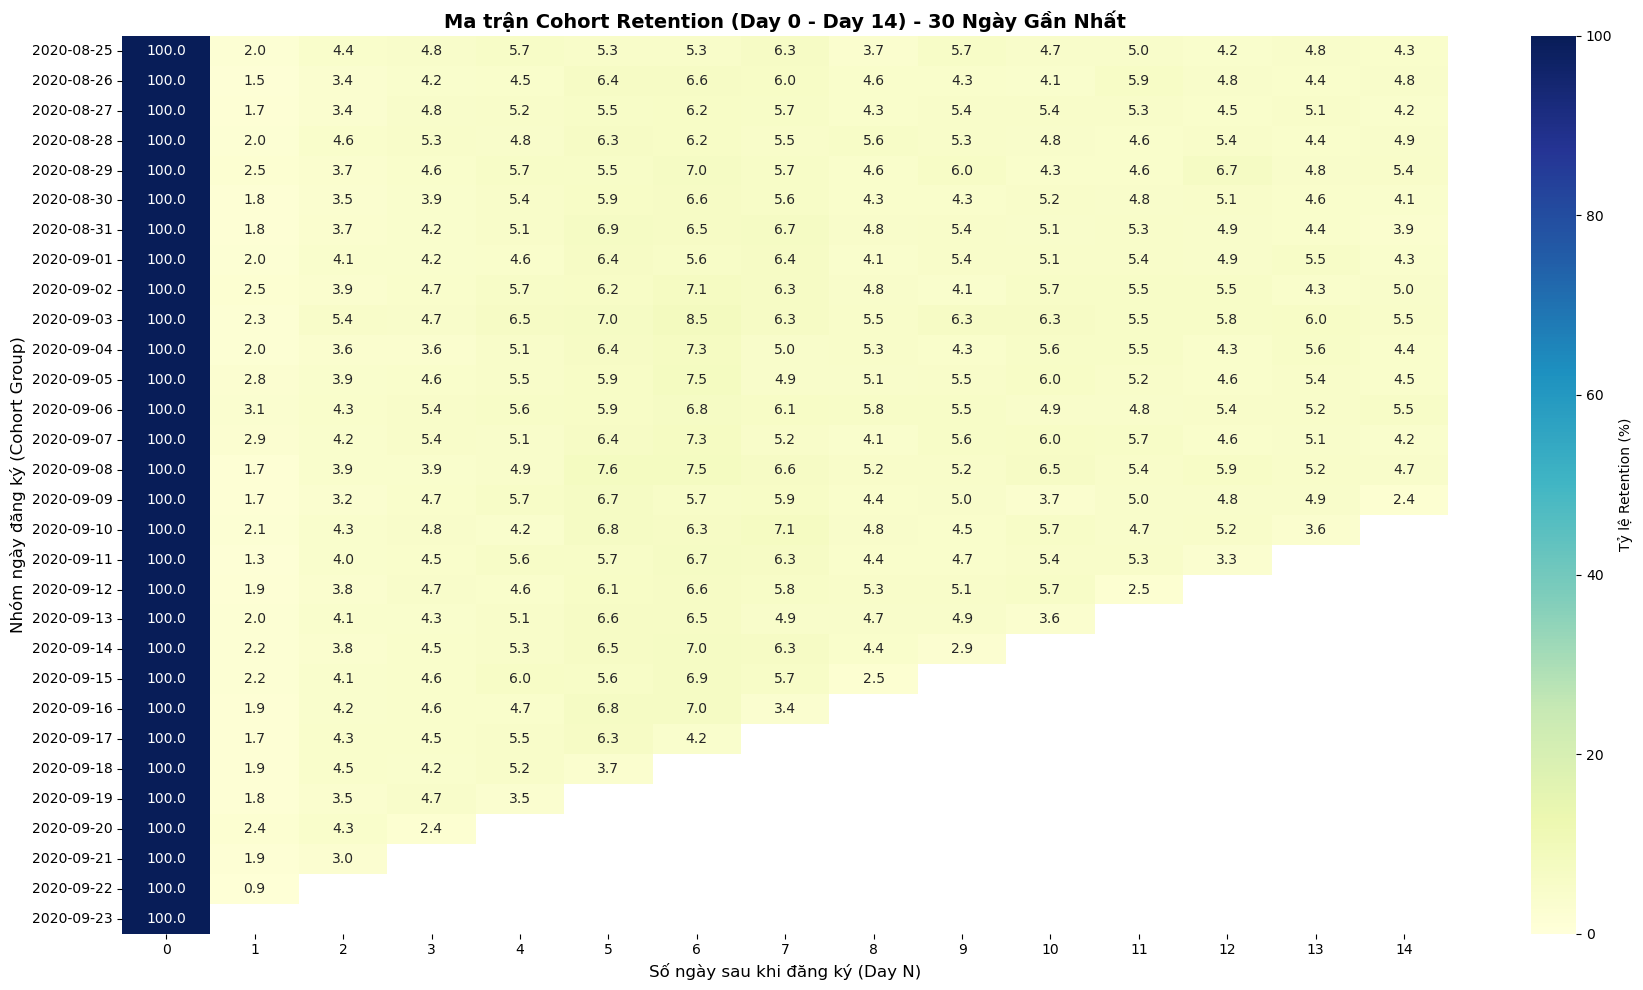

In [4]:
plt.figure(figsize=(18, 10))
sns.heatmap(
    retention_matrix.iloc[:, :15], # Hiển thị từ Day 0 đến Day 14 cho dễ nhìn
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Tỷ lệ Retention (%)'}
)

plt.title('Ma trận Cohort Retention (Day 0 - Day 14) - 30 Ngày Gần Nhất', fontsize=14, weight='bold')
plt.xlabel('Số ngày sau khi đăng ký (Day N)', fontsize=12)
plt.ylabel('Nhóm ngày đăng ký (Cohort Group)', fontsize=12)
plt.tight_layout()
plt.show()

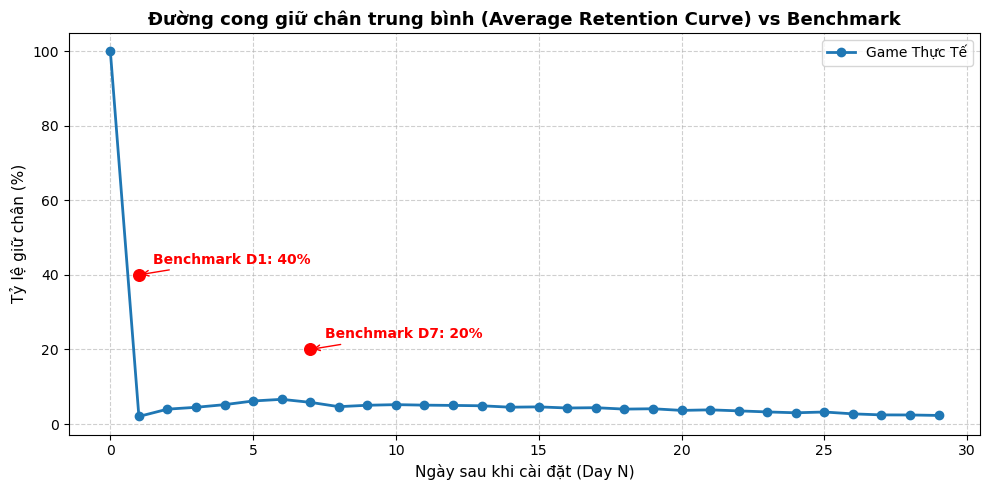

=== CHỈ SỐ RETENTION CỐT LÕI ===
Day 01 Retention: 2.02%
Day 03 Retention: 4.48%
Day 07 Retention: 5.81%
Day 14 Retention: 4.51%


In [5]:
# Tính tỷ lệ giữ chân trung bình qua các ngày
avg_retention = retention_matrix.mean(axis=0)[:30]

# Dựng biểu đồ so sánh với Benchmark
plt.figure(figsize=(10, 5))
plt.plot(avg_retention.index, avg_retention.values, marker='o', linewidth=2, color='#1f77b4', label='Game Thực Tế')

# Đánh dấu các mốc chuẩn ngành (Industry Benchmark 40-20-10)
benchmarks = {1: 40, 7: 20, 30: 10}
for day, rate in benchmarks.items():
    if day in avg_retention.index:
        plt.scatter(day, rate, color='red', s=70, zorder=5)
        plt.annotate(f'Benchmark D{day}: {rate}%', 
                     xy=(day, rate), 
                     xytext=(day + 0.5, rate + 3),
                     arrowprops=dict(arrowstyle="->", color='red'),
                     fontweight='bold', color='red')

plt.title('Đường cong giữ chân trung bình (Average Retention Curve) vs Benchmark', fontsize=13, weight='bold')
plt.xlabel('Ngày sau khi cài đặt (Day N)', fontsize=11)
plt.ylabel('Tỷ lệ giữ chân (%)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# In bảng tóm tắt chỉ số quan trọng
print("=== CHỈ SỐ RETENTION CỐT LÕI ===")
for d in [1, 3, 7, 14, 30]:
    if d in avg_retention.index:
        print(f"Day {d:02d} Retention: {avg_retention[d]:.2f}%")

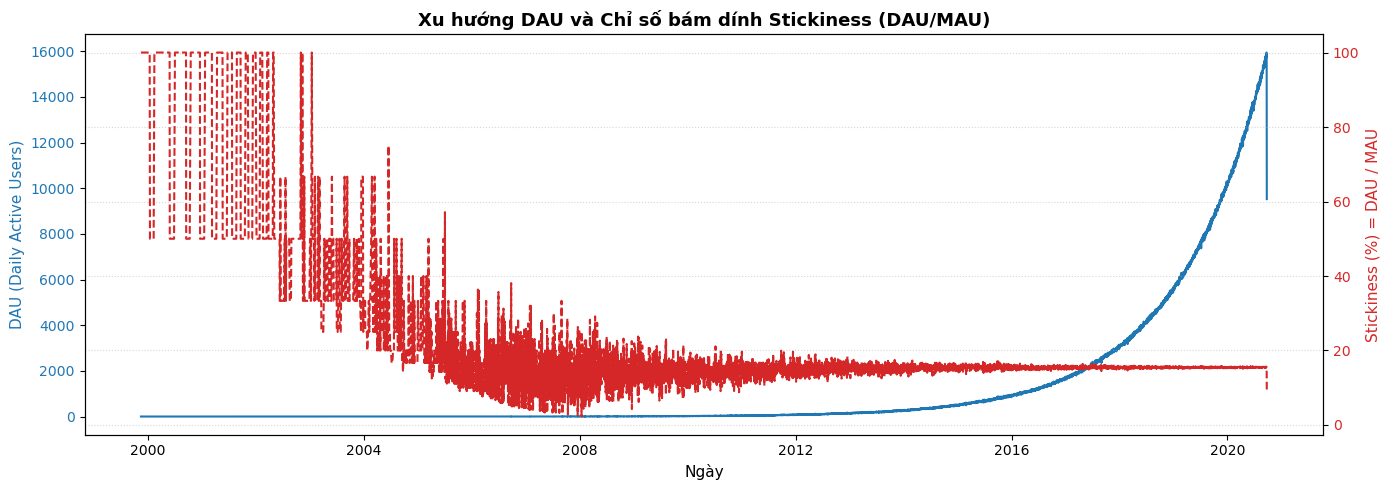

Stickiness trung bình: 18.58%


In [6]:
# ==========================================
# CELL 6: TÍNH DAU VÀ STICKINESS RATIO
# ==========================================

# 1. Tính DAU (Daily Active Users)
dau = auth_df.groupby('auth_date')['uid'].nunique().reset_index()
dau.columns = ['date', 'dau']

# 2. Tính MAU rolling 30 ngày (Monthly Active Users)
# Chuyển đổi sang datetime để tính cửa sổ trượt
auth_df_sorted = auth_df.sort_values('auth_date')

mau_records = []
dates = dau['date'].unique()

for current_date in dates:
    start_date = current_date - pd.Timedelta(days=29)
    # Đếm số user active duy nhất trong 30 ngày qua
    active_in_window = auth_df[(auth_df['auth_date'] >= start_date) & 
                               (auth_df['auth_date'] <= current_date)]['uid'].nunique()
    mau_records.append({'date': current_date, 'mau': active_in_window})

engagement_df = pd.merge(dau, pd.DataFrame(mau_records), on='date')

# 3. Tính Stickiness (DAU / MAU)
engagement_df['stickiness_pct'] = (engagement_df['dau'] / engagement_df['mau']) * 100

# Lọc bỏ 30 ngày đầu tiên (vì chưa đủ dữ liệu cho MAU 30 ngày chuẩn)
engagement_df = engagement_df.iloc[30:].copy()

# 4. Trực quan hóa DAU và Stickiness
fig, ax1 = plt.subplots(figsize=(14, 5))

color = 'tab:blue'
ax1.set_xlabel('Ngày', fontsize=11)
ax1.set_ylabel('DAU (Daily Active Users)', color=color, fontsize=11)
ax1.plot(engagement_df['date'], engagement_df['dau'], color=color, linewidth=1.5)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:red'
ax2.set_ylabel('Stickiness (%) = DAU / MAU', color=color, fontsize=11)
ax2.plot(engagement_df['date'], engagement_df['stickiness_pct'], color=color, linewidth=1.5, linestyle='--')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Xu hướng DAU và Chỉ số bám dính Stickiness (DAU/MAU)', fontsize=13, weight='bold')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Stickiness trung bình: {engagement_df['stickiness_pct'].mean():.2f}%")